<a href="https://colab.research.google.com/github/germfsip/Inteligencia-Artificial-y-Machine-Learning-para-organizaciones/blob/main/UNIR_AA_Lab_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DR# Introducción al aprendizaje automático · Cuaderno práctico

**Inteligencia Artificial y Aprendizaje Automático para las Organizaciones** · UNIR México
Clase 1 · Tema 1 · Mtro. Gerardo Adrián Martínez Fernández

---

En este cuaderno recorrerás, con un caso de negocio, todo lo que vimos en la Clase 1: el ciclo del dato, los tipos de aprendizaje y el vocabulario de scikit-learn (`fit`, `transform`, `predict`).

**No necesitas saber programar.** El cuaderno está pensado para ejecutarse y observar. Solo en tres **retos** se te pide cambiar un número y volver a ejecutar.

### Cómo usarlo
1. En el menú, elige **Archivo → Guardar una copia en Drive** para trabajar sobre tu propia copia.
2. Ejecuta las celdas **en orden**: haz clic en una celda de código y pulsa **Shift + Enter**. También puedes usar **Entorno de ejecución → Ejecutar todas**.
3. Lee el texto que acompaña a cada celda: ahí está la interpretación de negocio.

**Tiempo estimado:** 40 a 50 minutos.

## El caso: cancelación de pólizas en una aseguradora

Una aseguradora observa que alrededor de uno de cada cinco clientes cancela su póliza cada año. El área comercial quiere **anticipar quién está en riesgo** para que el equipo de retención actúe a tiempo, y además **entender qué tipos de clientes tiene**.

Seguiremos las fases de **CRISP-DM** que vimos en clase:

| Fase CRISP-DM | Sección del cuaderno |
|---|---|
| 1 · Entendimiento del negocio | Este texto |
| 2 · Entendimiento de los datos | Sección 1 |
| 3 · Preparación de los datos | Secciones 2 y 3 |
| 4 · Modelado | Secciones 4 y 5 |
| 5 · Evaluación | Tema 2 (próxima clase) |
| 6 · Despliegue | Sección 4.3, a modo de ilustración |

> **Criterio de éxito acordado con el negocio:** identificar a los clientes con mayor probabilidad de cancelar y explicar por qué.

**Nota:** los datos son **sintéticos**; se generan dentro del cuaderno para que no dependas de descargas. Imitan el comportamiento de una cartera real, pero no corresponden a ninguna empresa.

## 0 · Preparar el entorno

Esta celda importa las bibliotecas que usaremos. Todas vienen instaladas en Google Colab.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})
print("scikit-learn versión", sklearn.__version__)

scikit-learn versión 1.6.1


La siguiente celda **genera la cartera de clientes**. No necesitas entender su contenido; basta con ejecutarla.

In [2]:
# Generación de datos sintéticos (no es necesario modificar esta celda)
rng = np.random.default_rng(42)
n = 800

canal = rng.choice(["Agente", "Digital", "Banca"], n, p=[0.45, 0.35, 0.20])
antiguedad_meses = rng.integers(1, 121, n)
edad = rng.integers(20, 76, n).astype(float)
prima_mensual = np.clip(np.round(350 + 9 * (edad - 20) - 60 * (canal == "Digital") + rng.normal(0, 110, n)), 200, None)
num_reclamaciones = rng.poisson(0.8, n)
satisfaccion = np.clip(np.round(rng.normal(3.7, 0.9, n) - 0.45 * num_reclamaciones), 1, 5)
uso_app_mensual = rng.poisson(np.where(canal == "Digital", 7, 2))

logit = (-0.6 - 0.03 * antiguedad_meses + 0.6 * num_reclamaciones - 0.8 * (satisfaccion - 3.5)
         + 0.002 * (prima_mensual - 650) + 0.4 * (canal == "Digital"))
cancelo = rng.binomial(1, 1 / (1 + np.exp(-logit)))

comentarios_neg = ["Tardaron mucho en pagar mi reclamación", "El precio subió sin aviso", "Nadie me contestó en el call center"]
comentarios_pos = ["Buen servicio de mi agente", "La app es fácil de usar", "Resolvieron rápido mi siniestro"]
comentario = np.where(rng.random(n) < 0.6,
                      np.where(cancelo == 1, rng.choice(comentarios_neg, n), rng.choice(comentarios_pos, n)),
                      "Sin comentarios")

# Simulamos datos faltantes, como ocurre en cualquier sistema real
satisfaccion[rng.random(n) < 0.08] = np.nan
edad[rng.random(n) < 0.04] = np.nan

df = pd.DataFrame({
    "edad": edad, "canal": canal, "antiguedad_meses": antiguedad_meses, "prima_mensual": prima_mensual,
    "num_reclamaciones": num_reclamaciones, "satisfaccion": satisfaccion, "uso_app_mensual": uso_app_mensual,
    "comentario": comentario, "cancelo": cancelo,
})
print(f"Cartera generada: {df.shape[0]} clientes y {df.shape[1]} columnas")

Cartera generada: 800 clientes y 9 columnas


## 1 · Entender los datos *(CRISP-DM, fase 2)*

### 1.1 Un primer vistazo

In [3]:
df.head(8)

,edad,canal,antiguedad_meses,prima_mensual,num_reclamaciones,satisfaccion,uso_app_mensual,comentario,cancelo
0,20.0,Digital,37,247.0,2,1.0,9,Sin comentarios,1
1,51.0,Agente,89,644.0,1,2.0,1,La app es fácil de usar,0
2,61.0,Banca,100,629.0,0,5.0,1,Resolvieron rápido mi siniestro,0
3,50.0,Digital,39,434.0,0,5.0,8,Buen servicio de mi agente,0
4,41.0,Agente,15,436.0,1,2.0,1,Resolvieron rápido mi siniestro,0
5,66.0,Banca,107,694.0,1,NaN,2,Buen servicio de mi agente,0
6,40.0,Digital,18,342.0,0,4.0,6,Sin comentarios,0
7,59.0,Digital,72,659.0,1,NaN,7,Sin comentarios,0


**Qué observar:**
- Cada fila es un cliente y cada columna una característica: es **información estructurada**.
- La columna `comentario` es **texto libre**, es decir, **información no estructurada**. Para usarla en un modelo habría que procesarla con técnicas de lenguaje natural (Tema 8), así que hoy la dejaremos fuera.
- La columna `cancelo` (1 = canceló, 0 = no canceló) es nuestra **variable objetivo o target**.

### 1.2 Tipos de dato y valores faltantes

In [4]:
resumen = pd.DataFrame({"tipo": df.dtypes.astype(str), "faltantes": df.isna().sum(), "% faltantes": (df.isna().mean() * 100).round(1)})
resumen

,tipo,faltantes,% faltantes
edad,float64,25,3.1
canal,object,0,0.0
antiguedad_meses,int64,0,0.0
prima_mensual,float64,0,0.0
num_reclamaciones,int64,0,0.0
satisfaccion,float64,62,7.8
uso_app_mensual,int64,0,0.0
comentario,object,0,0.0
cancelo,int64,0,0.0


**Qué observar:** `satisfaccion` y `edad` tienen huecos. Antes de modelar hay que decidir qué hacer con ellos; lo resolveremos en la sección 2 con `SimpleImputer`.

### 1.3 Estadística descriptiva

In [5]:
df.describe().T[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
edad,47.64,16.19,20.0,47.0,75.0
antiguedad_meses,59.97,34.61,1.0,57.5,120.0
prima_mensual,569.74,185.00,200.0,568.0,1123.0
num_reclamaciones,0.82,0.92,0.0,1.0,6.0
satisfaccion,3.31,1.00,1.0,3.0,5.0
uso_app_mensual,3.76,3.08,0.0,3.0,16.0
cancelo,0.21,0.41,0.0,0.0,1.0


### 1.4 ¿Qué relación tienen las variables con la cancelación?

Tasa global de cancelación: 21.4%


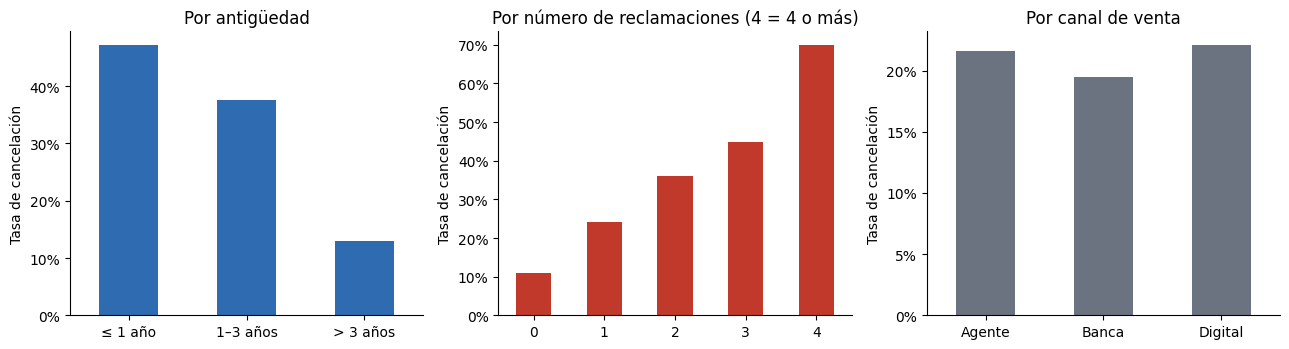

In [6]:
print(f"Tasa global de cancelación: {df['cancelo'].mean():.1%}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
tramos = pd.cut(df["antiguedad_meses"], [0, 12, 36, 120], labels=["≤ 1 año", "1–3 años", "> 3 años"])
df.groupby(tramos, observed=True)["cancelo"].mean().plot.bar(ax=axes[0], color="#2F6BB0", rot=0)
axes[0].set_title("Por antigüedad"); axes[0].set_xlabel("")

df.groupby(df["num_reclamaciones"].clip(upper=4))["cancelo"].mean().plot.bar(ax=axes[1], color="#C0392B", rot=0)
axes[1].set_title("Por número de reclamaciones (4 = 4 o más)"); axes[1].set_xlabel("")

df.groupby("canal")["cancelo"].mean().plot.bar(ax=axes[2], color="#6B7280", rot=0)
axes[2].set_title("Por canal de venta"); axes[2].set_xlabel("")

for ax in axes:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_ylabel("Tasa de cancelación")
plt.tight_layout(); plt.show()

**Qué observar:**
- Los clientes **nuevos** cancelan mucho más que los antiguos.
- La cancelación **crece con cada reclamación**.
- El **canal** casi no marca diferencia.

Estas intuiciones son hipótesis. En la sección 3 veremos si una prueba estadística las respalda.

## 2 · Preparar los datos *(CRISP-DM, fase 3)*

Aquí aparecen los **transformers** de scikit-learn: objetos que primero **aprenden** algo de los datos con `.fit()` y después **los modifican** con `.transform()`.

### 2.1 Separar predictoras (X) y target (y)

In [7]:
y = df["cancelo"]
X = df.drop(columns=["cancelo", "comentario"])      # quitamos el target y el texto libre
X = pd.get_dummies(X, columns=["canal"], dtype=int)  # el canal (texto) se convierte en columnas 0/1
X.head()

,edad,antiguedad_meses,prima_mensual,num_reclamaciones,satisfaccion,uso_app_mensual,canal_Agente,canal_Banca,canal_Digital
0,20.0,37,247.0,2,1.0,9,0,0,1
1,51.0,89,644.0,1,2.0,1,1,0,0
2,61.0,100,629.0,0,5.0,1,0,1,0
3,50.0,39,434.0,0,5.0,8,0,0,1
4,41.0,15,436.0,1,2.0,1,1,0,0


`pd.get_dummies` convierte la variable categórica `canal` en tres columnas de 0 y 1, porque los modelos solo trabajan con números. A esto se le llama **codificación one-hot**.

### 2.2 Imputar faltantes con `SimpleImputer`

In [8]:
from sklearn.impute import SimpleImputer

columnas_con_nulos = ["edad", "satisfaccion"]
imputador = SimpleImputer(strategy="mean")       # PARÁMETRO: lo decides tú antes de ajustar

imputador.fit(X[columnas_con_nulos])               # .fit() aprende la media de cada columna
print("Medias aprendidas (atributo statistics_):", imputador.statistics_.round(2))

X_imp = X.copy()
X_imp[columnas_con_nulos] = imputador.transform(X[columnas_con_nulos])   # .transform() rellena los huecos
print("Faltantes después de imputar:", int(X_imp.isna().sum().sum()))

Medias aprendidas (atributo statistics_): [47.64  3.31]
Faltantes después de imputar: 0


Fíjate en la diferencia que vimos en clase:
- **Parámetro:** `strategy="mean"`, que tú configuras **antes** de ajustar el objeto.
- **Atributo:** `statistics_`, que el objeto **aprende** con `.fit()`. Por convención, los atributos terminan en guion bajo.

> ### 🧩 Reto 1 · Cambia la estrategia de imputación
> En la celda anterior, cambia `strategy="mean"` por `strategy="median"` y vuelve a ejecutarla.
>
> **Pregunta:** ¿cambian los valores de `statistics_`? ¿Por qué la mediana puede ser preferible cuando hay valores extremos?

<details><summary><b>Respuesta orientativa</b> (ábrela después de intentarlo)</summary>

Los valores cambian: la edad pasa de 47.64 a 47.0 y la satisfacción de 3.31 a 3.0. Con la mediana, el valor imputado de satisfacción sí existe en la escala de 1 a 5, cosa que no ocurre con 3.31. La mediana no se deja arrastrar por valores extremos; por eso es preferible en variables asimétricas, como ingresos o montos de siniestros.
</details>

**Antes de continuar, regresa la estrategia a `"mean"` y vuelve a ejecutar la celda** para que tus resultados coincidan con los del resto del cuaderno.

### 2.3 Escalar con `MinMaxScaler`

In [9]:
from sklearn.preprocessing import MinMaxScaler

escalador = MinMaxScaler()
X_esc = pd.DataFrame(escalador.fit_transform(X_imp), columns=X_imp.columns)   # fit + transform en un paso

comparacion = pd.DataFrame({"mín. original": escalador.data_min_, "máx. original": escalador.data_max_,
                            "mín. escalado": X_esc.min().values, "máx. escalado": X_esc.max().values},
                           index=X_imp.columns)
comparacion

,mín. original,máx. original,mín. escalado,máx. escalado
edad,20.0,75.0,0.0,1.0
antiguedad_meses,1.0,120.0,0.0,1.0
prima_mensual,200.0,1123.0,0.0,1.0
num_reclamaciones,0.0,6.0,0.0,1.0
satisfaccion,1.0,5.0,0.0,1.0
uso_app_mensual,0.0,16.0,0.0,1.0
canal_Agente,0.0,1.0,0.0,1.0
canal_Banca,0.0,1.0,0.0,1.0
canal_Digital,0.0,1.0,0.0,1.0


**Qué observar:** cada variable queda entre 0 y 1. Antes, `prima_mensual` (cientos de pesos) y `num_reclamaciones` (de 0 a 5) estaban en escalas muy distintas. Los algoritmos que miden distancias, como K-Means o KNN, se dejarían dominar por la variable de mayor magnitud.

`.fit_transform()` es simplemente `.fit()` seguido de `.transform()`.

## 3 · Seleccionar variables con chi² *(CRISP-DM, fase 3)*

La prueba **chi²** mide si cada variable es independiente del target. De ella obtenemos dos números:
- el **estadístico chi²**: cuanto más alto, más relación con la cancelación;
- el **p-valor**: si es menor que 0.05, la relación es estadísticamente significativa.

In [10]:
from sklearn.feature_selection import chi2

estadisticos, p_valores = chi2(X_esc, y)
ranking = (pd.DataFrame({"chi²": estadisticos, "p-valor": p_valores}, index=X_esc.columns)
           .sort_values("chi²", ascending=False))
ranking["¿significativa?"] = np.where(ranking["p-valor"] < 0.05, "Sí", "No")
ranking.style.format({"chi²": "{:.2f}", "p-valor": "{:.4f}"})

,chi²,p-valor,¿significativa?
antiguedad_meses,15.80,0.0001,Sí
num_reclamaciones,10.84,0.0010,Sí
satisfaccion,6.13,0.0133,Sí
prima_mensual,0.88,0.3475,No
edad,0.88,0.3494,No
canal_Banca,0.33,0.5663,No
uso_app_mensual,0.20,0.6509,No
canal_Digital,0.09,0.7636,No
canal_Agente,0.01,0.9145,No


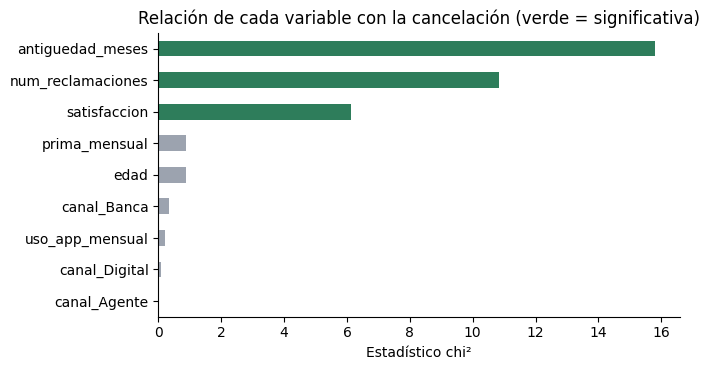

In [11]:
colores = ["#2E7D5B" if s == "Sí" else "#9CA3AF" for s in ranking["¿significativa?"]]
ranking["chi²"].sort_values().plot.barh(color=colores[::-1], figsize=(7, 3.8))
plt.title("Relación de cada variable con la cancelación (verde = significativa)")
plt.xlabel("Estadístico chi²"); plt.tight_layout(); plt.show()

**Qué observar:** la prueba **confirma lo que intuimos** en la sección 1.4. Antigüedad, reclamaciones y satisfacción están relacionadas con la cancelación; el canal no lo está.

**Precisiones:**
- chi² fue diseñada para variables de conteo o categóricas y exige valores no negativos. Por eso la aplicamos sobre los datos escalados; aquí la usamos con fines ilustrativos.
- Recuerda la fe de erratas del manual: los primeros números que devuelve `chi2` son **estadísticos**, no p-valores.

## 4 · Aprendizaje supervisado *(CRISP-DM, fase 4)*

Ahora sí **hay un target**: queremos aprender a predecir `cancelo`, que es **categórico** (0 o 1). Se trata de un problema de **clasificación**.

### 4.1 Entrenar un árbol de decisión
Usamos un árbol porque su resultado **se puede leer** como un conjunto de reglas de negocio.

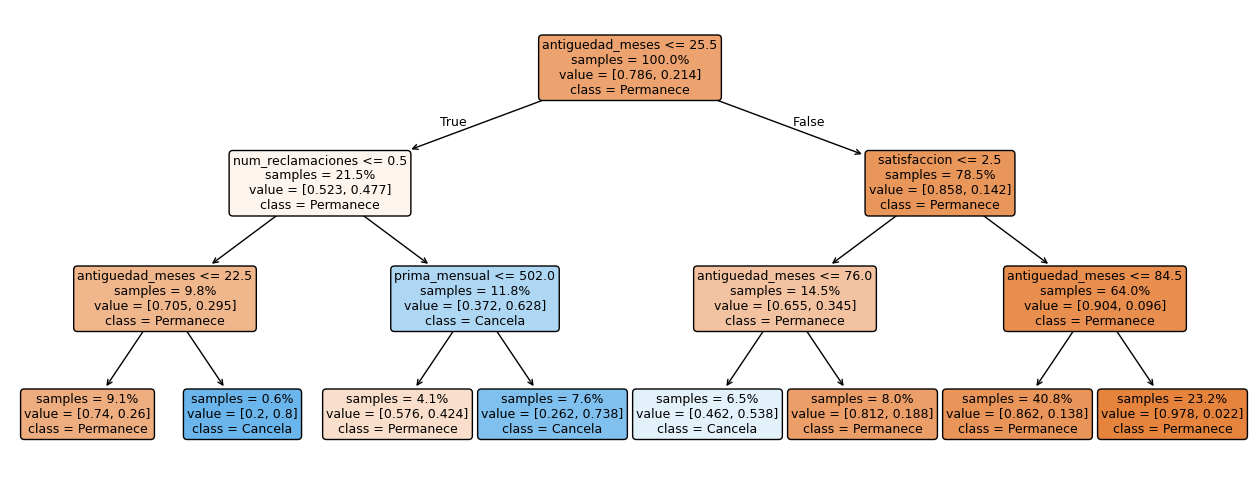

In [12]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

arbol = DecisionTreeClassifier(max_depth=3, random_state=42)   # max_depth es un PARÁMETRO
arbol.fit(X_imp, y)                                             # estimator: aprende de los datos

plt.figure(figsize=(16, 6))
plot_tree(arbol, feature_names=list(X_imp.columns), class_names=["Permanece", "Cancela"],
          filled=True, rounded=True, impurity=False, proportion=True, fontsize=9)
plt.show()

**Cómo leer el árbol:** cada caja hace una pregunta (por ejemplo, la primera es `antiguedad_meses <= 25.5`). Si la respuesta es sí, sigues la rama izquierda; si es no, la derecha. Las cajas finales indican la proporción de clientes que cancelan en ese grupo, y su color se intensifica cuanto más claro es el resultado.

**Detalle técnico:** entrenamos el árbol con los datos **sin escalar** (`X_imp`). Los árboles no necesitan escalado, y así los umbrales se leen en unidades reales: meses, número de reclamaciones o puntos de satisfacción.

### 4.2 ¿Qué variables usó el modelo?

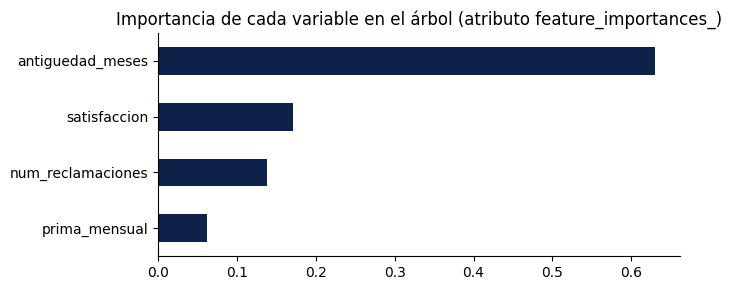

In [13]:
importancia = pd.Series(arbol.feature_importances_, index=X_imp.columns).sort_values()
importancia[importancia > 0].plot.barh(color="#0E2148", figsize=(7, 3))
plt.title("Importancia de cada variable en el árbol (atributo feature_importances_)")
plt.tight_layout(); plt.show()

### 4.3 Predecir para clientes nuevos *(una idea de despliegue)*

Una vez entrenado, el árbol funciona como **predictor**. Imagina que el CRM envía estos tres clientes al modelo:

In [14]:
nuevos = pd.DataFrame({
    "edad": [28, 55, 41], "antiguedad_meses": [4, 96, 20], "prima_mensual": [520, 780, 640],
    "num_reclamaciones": [3, 0, 1], "satisfaccion": [2, 5, 3], "uso_app_mensual": [9, 1, 3],
    "canal_Agente": [0, 1, 0], "canal_Banca": [0, 0, 1], "canal_Digital": [1, 0, 0],
}, index=["Cliente A", "Cliente B", "Cliente C"])[X_imp.columns]

resultado = nuevos[["antiguedad_meses", "num_reclamaciones", "satisfaccion"]].copy()
resultado["predicción (.predict)"] = np.where(arbol.predict(nuevos) == 1, "Cancela", "Permanece")
resultado["probabilidad de cancelar (.predict_proba)"] = arbol.predict_proba(nuevos)[:, 1].round(2)
resultado

,antiguedad_meses,num_reclamaciones,satisfaccion,predicción (.predict),probabilidad de cancelar (.predict_proba)
Cliente A,4,3,2,Cancela,0.74
Cliente B,96,0,5,Permanece,0.02
Cliente C,20,1,3,Cancela,0.74


**Qué observar:**
- `.predict()` devuelve la **clase**: cancela o permanece.
- `.predict_proba()` devuelve la **probabilidad**. Para el negocio suele ser más útil, porque permite **priorizar** a quién llama primero el equipo de retención.

> ⚠️ **Todavía no sabemos si el modelo es bueno.** Lo entrenamos y lo usamos con los mismos datos, lo cual da una impresión optimista. **Cómo evaluarlo correctamente es justo el Tema 2.**

> ### 🧩 Reto 2 · Cambia la profundidad del árbol
> En la celda de la sección 4.1, cambia `max_depth=3` por `max_depth=1` y ejecuta. Después prueba con `max_depth=6`.
>
> **Preguntas:** ¿cuál de los dos árboles podrías explicarle a un director comercial? ¿Cuál crees que se está "aprendiendo de memoria" los datos?

<details><summary><b>Respuesta orientativa</b></summary>

Con `max_depth=1` el árbol hace una sola pregunta, casi siempre sobre la antigüedad: es fácil de explicar, pero muy simple. Con `max_depth=6` aparecen decenas de reglas muy específicas: es difícil de comunicar y probablemente memoriza particularidades de estos 800 clientes. Ese fenómeno, el **sobreajuste**, se mide en el Tema 2 y se controla en el Tema 7.
</details>

**Regresa a `max_depth=3` y vuelve a ejecutar las celdas 4.1 a 4.3 antes de continuar.**

### 4.4 El mismo vocabulario, ahora en regresión

Si el target es **numérico continuo**, el problema es de **regresión**. Por ejemplo, el área de suscripción quiere **estimar la prima mensual** de un cliente a partir de su edad y su canal de venta.

In [15]:
from sklearn.linear_model import LinearRegression

X_reg = X_imp[["edad", "canal_Agente", "canal_Banca", "canal_Digital"]]
regresion = LinearRegression()
regresion.fit(X_reg, df["prima_mensual"])

print("Atributos aprendidos:")
print(f"  intercept_ = {regresion.intercept_:,.1f}")
for nombre, coef in zip(X_reg.columns, regresion.coef_):
    print(f"  coef_ {nombre:<15} = {coef:+,.1f}")

cliente = pd.DataFrame({"edad": [40], "canal_Agente": [0], "canal_Banca": [0], "canal_Digital": [1]})
print(f"\nPrima estimada para un cliente de 40 años del canal digital: ${regresion.predict(cliente)[0]:,.0f} al mes")

Atributos aprendidos:
  intercept_ = 135.6
  coef_ edad            = +9.1
  coef_ canal_Agente    = +21.9
  coef_ canal_Banca     = +11.4
  coef_ canal_Digital   = -33.2

Prima estimada para un cliente de 40 años del canal digital: $467 al mes


**Qué observar:** el código es **casi idéntico** al de clasificación: `.fit()` para aprender y `.predict()` para estimar. Lo que cambia es el tipo de target y, por eso, el algoritmo.

El coeficiente de `edad` indica cuántos pesos aumenta la prima, en promedio, por cada año adicional de edad. Los coeficientes de canal se interpretan en relación con los otros canales.

## 5 · Aprendizaje no supervisado

Ahora **olvidamos el target**. La pregunta ya no es quién cancelará, sino **qué tipos de clientes tenemos**. Es un problema de **segmentación (clustering)**.

### 5.1 Segmentar con K-Means

In [16]:
from sklearn.cluster import KMeans

variables_perfil = ["edad", "antiguedad_meses", "prima_mensual", "num_reclamaciones", "satisfaccion", "uso_app_mensual"]
X_seg = X_esc[variables_perfil]                    # K-Means usa distancias: necesita datos escalados

kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
df["segmento"] = kmeans.fit_predict(X_seg)

perfil = df.groupby("segmento")[variables_perfil].mean()
perfil.insert(0, "clientes", df["segmento"].value_counts().sort_index())
perfil

,clientes,edad,antiguedad_meses,prima_mensual,num_reclamaciones,satisfaccion,uso_app_mensual
segmento,,,,,,,
0,260,38.14,28.80,466.40,0.82,3.26,4.07
1,290,65.04,59.44,750.51,0.73,3.45,3.57
2,250,36.89,93.00,467.52,0.94,3.19,3.65


**Qué observar:** cada fila es un segmento descrito por el **promedio** de sus variables. El algoritmo no sabe qué significan los grupos; **ponerles nombre es trabajo del analista y del negocio**. En esta cartera, por ejemplo, aparecen "jóvenes recién llegados" (poca antigüedad), "clientes maduros de prima alta" y "jóvenes leales" (mucha antigüedad).

### 5.2 Visualizar los segmentos con PCA

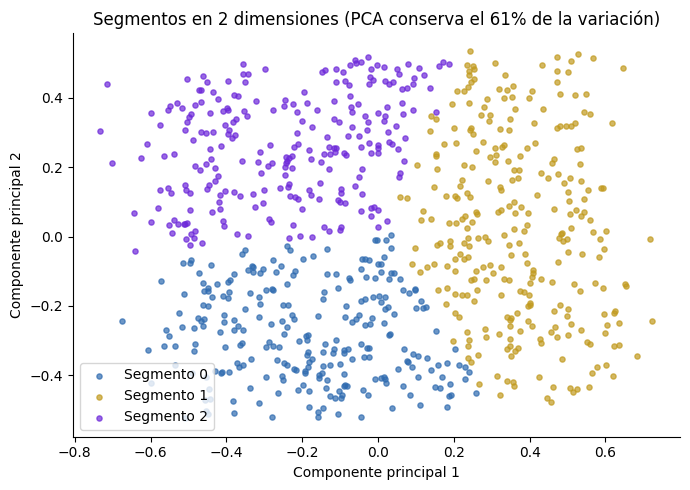

In [17]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_seg)          # de 6 variables a 2: reducción de dimensionalidad

plt.figure(figsize=(7, 5))
colores_seg = ["#2F6BB0", "#C19A1F", "#6D28D9", "#2E7D5B", "#C0392B", "#6B7280"]
for s in sorted(df["segmento"].unique()):
    m = df["segmento"] == s
    plt.scatter(coords[m, 0], coords[m, 1], s=14, alpha=0.7, color=colores_seg[s % 6], label=f"Segmento {s}")
plt.xlabel("Componente principal 1"); plt.ylabel("Componente principal 2")
plt.title(f"Segmentos en 2 dimensiones (PCA conserva el {pca.explained_variance_ratio_.sum():.0%} de la variación)")
plt.legend(); plt.tight_layout(); plt.show()

**Qué observar:** PCA es otra técnica no supervisada. Comprime las 6 variables en 2 para poder **dibujarlas**. Los grupos que encontró K-Means se ven como nubes de distinto color.

### 5.3 Conectar la segmentación con el negocio

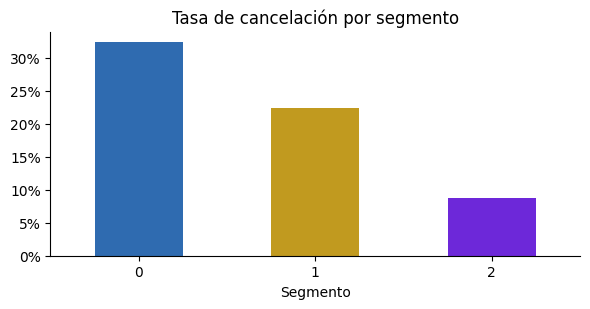

In [18]:
(df.groupby("segmento")["cancelo"].mean()
   .plot.bar(color=[colores_seg[s % 6] for s in sorted(df["segmento"].unique())], rot=0, figsize=(6, 3.2)))
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.title("Tasa de cancelación por segmento"); plt.ylabel(""); plt.xlabel("Segmento")
plt.tight_layout(); plt.show()

**Qué observar:** K-Means **nunca vio** la columna `cancelo` y, aun así, algunos segmentos cancelan bastante más que otros. Así se complementan ambos enfoques: el **no supervisado** describe la cartera y el **supervisado** predice el riesgo de cada cliente.

> ### 🧩 Reto 3 · ¿Cuántos segmentos?
> En la celda 5.1, cambia `n_clusters=3` por `n_clusters=4` y ejecuta las celdas 5.1 a 5.3.
>
> **Preguntas:** ¿el nuevo segmento aporta un perfil distinto o solo divide uno que ya existía? ¿Con cuántos segmentos podría trabajar realmente un área de marketing?

<details><summary><b>Respuesta orientativa</b></summary>

No existe un número "correcto" de segmentos: es una decisión de negocio apoyada en datos. Un segmento solo vale la pena si es **distinto**, lo bastante **grande** y **accionable**, es decir, si justifica una estrategia propia. Existen métodos para orientar esta elección, como el del codo o el coeficiente de silueta, que se ven en el Tema 4.
</details>

## 6 · Recapitulación

| Objeto de scikit-learn | Tipo | Método principal | Lo usamos para |
|---|---|---|---|
| `SimpleImputer` | Transformer | `.fit()` / `.transform()` | Rellenar faltantes |
| `MinMaxScaler` | Transformer | `.fit_transform()` | Llevar variables a [0, 1] |
| `chi2` | Función | — | Medir relación con el target |
| `DecisionTreeClassifier` | Predictor | `.fit()` / `.predict_proba()` | Clasificar riesgo de cancelación |
| `LinearRegression` | Predictor | `.fit()` / `.predict()` | Estimar la prima (regresión) |
| `KMeans` | Estimator | `.fit_predict()` | Segmentar clientes |
| `PCA` | Transformer | `.fit_transform()` | Reducir a 2 dimensiones |

**Ideas clave:**
1. El mismo flujo de CRISP-DM sirvió para dos preguntas de negocio distintas.
2. La existencia de un target decide si el problema es supervisado o no supervisado. Su tipo, categórico o numérico, decide entre clasificación y regresión.
3. scikit-learn usa el mismo vocabulario para todo: `fit`, `transform`, `predict`.
4. Aún falta lo más importante antes de desplegar: **evaluar** el modelo. Eso lo veremos en la Clase 2.

## Anexo · El código del manual, corregido

Estos son los fragmentos de la sección 1.5 del manual del Tema 1, con sus errores de transcripción corregidos. Cada corrección está señalada con un comentario `# CORREGIDO`.

In [19]:
# sklearn.datasets — CORREGIDO: el módulo es "datasets" (en plural)
from sklearn.datasets import load_iris
iris = load_iris()
print(iris.data.shape, list(iris.target_names))

(150, 4) [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


In [20]:
# sklearn.preprocessing — CORREGIDO: datos coherentes con la salida y paréntesis de cierre en print
from sklearn.preprocessing import MinMaxScaler
data = [[-1, 2], [-0.5, 6], [0, 10], [1, 18]]
scaler = MinMaxScaler()
scaler.fit(data)
print(scaler.transform(data))

[[0.   0.  ]
 [0.25 0.25]
 [0.5  0.5 ]
 [1.   1.  ]]


In [21]:
# sklearn.impute — CORREGIDO: "import numpy as np", paréntesis de cierre y se imprime el imputador (no el scaler)
import numpy as np
from sklearn.impute import SimpleImputer
data = [[np.nan, 2, 3], [4, np.nan, 6], [10, np.nan, 9]]
imp_mean = SimpleImputer(missing_values=np.nan, strategy="mean")
imp_mean.fit(data)
print(imp_mean.transform(data))
# Nota: la 2.ª columna solo tiene un valor observado (2), así que la media imputada es 2.0 (el manual muestra 3.5)

[[ 7.  2.  3.]
 [ 4.  2.  6.]
 [10.  2.  9.]]


In [22]:
# sklearn.feature_selection — CORREGIDO: corchete de cierre en X y coma doble en y
import numpy as np
from sklearn.feature_selection import chi2
X = np.array([[1, 1, 3], [0, 1, 5], [5, 4, 1], [6, 6, 2], [1, 4, 0], [0, 0, 0]])
y = np.array([1, 1, 0, 0, 2, 2])
chi2_stats, p_values = chi2(X, y)
print("Estadísticos chi²:", chi2_stats.round(2))   # el manual presenta estos valores como si fueran p-valores
print("p-valores:        ", p_values.round(4))

Estadísticos chi²: [15.38  6.5   8.91]
p-valores:         [0.0005 0.0388 0.0116]


---
*Material complementario de la Clase 1 · IA y Aprendizaje Automático para las Organizaciones · UNIR México. Datos sintéticos generados con fines didácticos.*